# Exercice 2 — Normalisation et standardisation

In [1]:
import numpy as np

import pandas as pd

from sklearn.preprocessing import  StandardScaler , MinMaxScaler

import matplotlib.pyplot  as plt

### Chargement du dataset

In [9]:
df = pd.read_csv("dataset/ex1_dataset_traité.csv",index_col=False)

df = df.reset_index(drop=True)

### Sur les colonnes age, salaire_annuel, taille_cm : applique une standardisation (StandardScaler) dans une copie du DataFrame nommée df_standard

In [3]:
df_standard = df.copy()

normalise =  StandardScaler()

df_standard[["age","salaire_annuel","taille_cm"]] = normalise.fit_transform(df_standard[["age","salaire_annuel","taille_cm"]])

df_standard

,age,salaire_annuel,taille_cm,niveau_education,ville,genre,statut_marital
0,0.393439,0.000000,-0.164586,Lycée,Nantes,Autre,Célibataire
1,0.000000,-1.501214,0.203601,Bac+2,Nantes,Femme,Célibataire
2,1.006807,-0.295520,0.645425,Lycée,Paris,Femme,Marié
3,1.211262,0.906482,-1.146417,Bac+5,Nice,Homme,Célibataire
4,-1.651119,-1.786359,-1.195508,Lycée,Paris,Femme,Célibataire
...,...,...,...,...,...,...,...
195,-1.037751,0.000000,2.670451,Bac+2,Toulouse,Femme,Célibataire
196,0.000000,0.496275,1.946351,Bac+2,Marseille,Femme,Célibataire
197,-0.424384,1.036037,-0.495954,Bac+5,Nice,Homme,Marié
198,-0.015472,0.000000,-0.446862,Bac+5,Nantes,Femme,Célibataire


### Appliquons séparément une normalisation min-max (MinMaxScaler) dans une copie nommée df_minmax

In [4]:
df_minmax = df.copy()

normalise = MinMaxScaler()

df_standard[["age","salaire_annuel","taille_cm"]] = normalise.fit_transform(df_standard[["age","salaire_annuel","taille_cm"]])


df_standard

,age,salaire_annuel,taille_cm,niveau_education,ville,genre,statut_marital
0,0.392157,0.468485,0.443975,Lycée,Nantes,Autre,Célibataire
1,0.316693,0.198995,0.507400,Bac+2,Nantes,Femme,Célibataire
2,0.509804,0.415435,0.583510,Lycée,Paris,Femme,Marié
3,0.549020,0.631212,0.274841,Bac+5,Nice,Homme,Célibataire
4,0.000000,0.147807,0.266385,Lycée,Paris,Femme,Célibataire
...,...,...,...,...,...,...,...
195,0.117647,0.468485,0.932347,Bac+2,Toulouse,Femme,Célibataire
196,0.316693,0.557574,0.807611,Bac+2,Marseille,Femme,Célibataire
197,0.235294,0.654469,0.386892,Bac+5,Nice,Homme,Marié
198,0.313725,0.468485,0.395349,Bac+5,Nantes,Femme,Célibataire


### Pour chacune des 3 colonnes, trace 3 histogrammes côte à côte (grille 1x3 avec Matplotlib, 30 bins chacun) : distribution brute / après standardisation / après normalisation min-max.

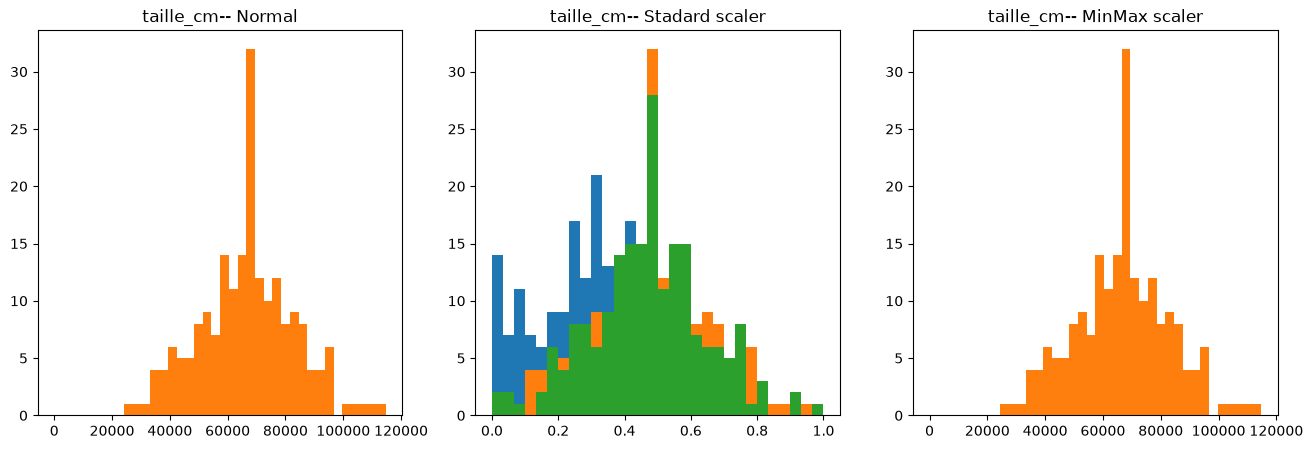

In [5]:
fig , ax = plt.subplots(1,3,figsize=(16,5))


col = df.columns[:3]

for c in col :

    ax[0].hist(df[c],bins=30)

    ax[0].set_title(f"{c}-- Normal")


    ax[1].hist(df_standard[c],bins=30)

    ax[1].set_title(f"{c}-- Stadard scaler")

    
    ax[2].hist(df_minmax[c],bins=30)

    ax[2].set_title(f"{c}-- MinMax scaler")


### Affichage pour chaque version la moyenne et l'écart-type de chaque colonne (.describe())

In [6]:
df.describe()

,age,salaire_annuel,taille_cm
count,200.000000,200.000000,200.000000
mean,34.151351,66622.572222,172.341053
std,9.806613,16288.669526,8.168489
min,18.000000,24220.000000,150.000000
25%,27.000000,57096.750000,167.650000
50%,34.151351,66622.572222,172.341053
75%,40.000000,77224.000000,177.525000
max,69.000000,114730.000000,197.300000


In [7]:
df_standard.describe()

,age,salaire_annuel,taille_cm
count,200.000000,200.000000,200.000000
mean,0.316693,0.468485,0.472327
std,0.192287,0.179965,0.172695
min,0.000000,0.000000,0.000000
25%,0.176471,0.363239,0.373150
50%,0.316693,0.468485,0.472327
75%,0.431373,0.585615,0.581924
max,1.000000,1.000000,1.000000


In [8]:
df_minmax.describe()

,age,salaire_annuel,taille_cm
count,200.000000,200.000000,200.000000
mean,34.151351,66622.572222,172.341053
std,9.806613,16288.669526,8.168489
min,18.000000,24220.000000,150.000000
25%,27.000000,57096.750000,167.650000
50%,34.151351,66622.572222,172.341053
75%,40.000000,77224.000000,177.525000
max,69.000000,114730.000000,197.300000


### Rédige 5 à 10 lignes expliquant dans quel cas tu choisirais la standardisation

Je choisirais StandardScaler pour les algorithmes comme SVM, LogisticRegression et PCA, qui sont sensibles à l'échelle des variables. Il centre les données autour de 0 avec un écart-type de 1. En présence d'outliers, je privilégierais plutôt RobustScaler.

Je choisirais MinMaxScaler pour les réseaux de neurones (MLPClassifier) et KNeighborsClassifier, lorsque je souhaite ramener les valeurs dans une plage connue, généralement entre 0 et 1. Il est cependant sensible aux valeurs extrêmes.